In [1]:

import os, sys, io, json, time, hashlib, subprocess, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

try:
    from IPython.display import display
except ImportError:                      # allows running the code outside Jupyter
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# ----- Global configuration (identical in all five notebooks) -----
SEED = 42                    # random seed for the split, weight initialisation and shuffling
TEST_SIZE = 0.20             # stratified 80/20 split
EPOCHS = 100                 # number of epochs for every optimizer
LAMBDA = 1e-3                # L2 regularisation strength
CLASS_NAMES = ["Dropout", "Enrolled", "Graduate"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
N_CLASSES = len(CLASS_NAMES)
RESULTS_DIR = "results"      # every notebook stores its results as JSON here
OPTIMIZER_SLUG = "mini-batch-gd"
OPTIMIZER_NAME = "Mini-Batch GD + Momentum"

np.random.seed(SEED)
print(f"numpy {np.__version__} | pandas {pd.__version__}")
print(f"SEED={SEED} | EPOCHS={EPOCHS} | LAMBDA={LAMBDA} | optimizer: {OPTIMIZER_NAME}")

numpy 2.1.3 | pandas 2.3.3
SEED=42 | EPOCHS=100 | LAMBDA=0.001 | optimizer: Mini-Batch GD + Momentum


In [2]:
# 3. Dataset Loading
UCI_ID = 697
ZIP_URL = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"


def _clean(df):
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df


def load_uci_dataset():
    """Return (features DataFrame, target Series of strings, source description)."""
    # 1) Official UCI python package
    try:
        try:
            from ucimlrepo import fetch_ucirepo
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--retries", "0",
                            "--timeout", "10", "ucimlrepo"], check=True, timeout=120, capture_output=True)
            from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=UCI_ID)
        return _clean(ds.data.features), ds.data.targets.iloc[:, 0].astype(str).str.strip(), "UCI via ucimlrepo"
    except Exception as exc:
        print("ucimlrepo not available:", repr(exc)[:120])
    # 2) Direct download of the official archive
    try:
        import urllib.request, zipfile
        with urllib.request.urlopen(ZIP_URL, timeout=60) as resp:
            payload = resp.read()
        with zipfile.ZipFile(io.BytesIO(payload)) as zf:
            with zf.open("data.csv") as fh:
                df = _clean(pd.read_csv(fh, sep=";"))
        return df.drop(columns=["Target"]), df["Target"].astype(str).str.strip(), "UCI zip archive"
    except Exception as exc:
        print("Direct download failed:", repr(exc)[:120])
    # 3) Offline fallback: the UCI data.csv attached to the notebook (e.g. Kaggle "Add Input") or placed next to it
    import glob
    candidates = ["data.csv"] + glob.glob("/kaggle/input/**/*.csv", recursive=True) + glob.glob("*.csv") + glob.glob("/content/*.csv")
    for path in candidates:
        for sep in (";", ","):
            try:
                df = _clean(pd.read_csv(path, sep=sep))
            except Exception:
                continue
            if "Target" in df.columns and df.shape[1] >= 30:
                print(f"Using local file: {path}")
                return df.drop(columns=["Target"]), df["Target"].astype(str).str.strip(), f"local file ({path})"
    raise RuntimeError(
        "Could not load the dataset.\n"
        "  Kaggle : either turn Internet ON (Settings sidebar), or click 'Add Input' and attach a dataset that contains the UCI data.csv.\n"
        "  Colab / local : upload data.csv (from the UCI zip archive) next to the notebook.")


X_raw, y_raw, DATA_SOURCE = load_uci_dataset()
assert set(y_raw.unique()) == set(CLASS_NAMES), f"Unexpected target labels: {y_raw.unique()}"
y_all = y_raw.map(CLASS_TO_ID).astype(int).values          # Dropout=0, Enrolled=1, Graduate=2

print(f"Data source : {DATA_SOURCE}")
print(f"Features    : {X_raw.shape[1]} | Samples: {X_raw.shape[0]}")
display(X_raw.head())

ucimlrepo not available: CalledProcessError(1, ['/usr/bin/python3', '-m', 'pip', 'install', '-q', '--retries', '0', '--timeout', '10', 'ucimlrepo
Direct download failed: URLError(gaierror(-3, 'Temporary failure in name resolution'))
Using local file: /kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv
Data source : local file (/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv)
Features    : 36 | Samples: 4424


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79


In [3]:
# 4. Exploratory Data Analysis
print("Shape:", X_raw.shape)
print("\nData types:\n", X_raw.dtypes.value_counts().to_string())
print("\nTotal missing values :", int(X_raw.isna().sum().sum()))
print("Duplicated rows       :", int(X_raw.assign(_y=y_all).duplicated().sum()))

Shape: (4424, 36)

Data types:
 int64      29
float64     7

Total missing values : 0
Duplicated rows       : 0


In [4]:
# 4.2 Feature types. Many integer columns are category CODES (course, application mode, qualifications, occupations, 
NOMINAL_NORMALISED = ["marital status", "application mode", "course", "previous qualification",
                      "nacionality", "mother's qualification", "father's qualification",
                      "mother's occupation", "father's occupation"]


def split_feature_types(X):
    norm = {c: c.strip().lower() for c in X.columns}
    nominal = [c for c in X.columns if norm[c] in NOMINAL_NORMALISED]
    missing = set(NOMINAL_NORMALISED) - {norm[c] for c in nominal}
    assert not missing, f"Nominal columns not found: {missing}"
    rest = [c for c in X.columns if c not in nominal]
    binary = [c for c in rest if X[c].nunique() == 2]               # 0/1 flags: kept as they are
    numerical = [c for c in rest if c not in binary]                # scaled with StandardScaler
    return nominal, binary, numerical


NOMINAL_COLS, BINARY_COLS, NUMERICAL_COLS = split_feature_types(X_raw)

type_table = pd.DataFrame({
    "feature type": ["Nominal categorical (One-Hot)", "Binary flag (kept 0/1)", "Numerical (StandardScaler)"],
    "count": [len(NOMINAL_COLS), len(BINARY_COLS), len(NUMERICAL_COLS)],
})
display(type_table)

cardinality = X_raw[NOMINAL_COLS].nunique().sort_values(ascending=False)
print("\nNumber of distinct categories per nominal feature:")
print(cardinality.to_string())
print(f"\nExpected number of One-Hot columns: {int(cardinality.sum())}")
print("\nBinary features  :", BINARY_COLS)
print("Numerical features:", len(NUMERICAL_COLS))

,feature type,count
0,Nominal categorical (One-Hot),9
1,Binary flag (kept 0/1),8
2,Numerical (StandardScaler),19



Number of distinct categories per nominal feature:
Father's occupation       46
Father's qualification    34
Mother's occupation       32
Mother's qualification    29
Nacionality               21
Application mode          18
Previous qualification    17
Course                    17
Marital status             6

Expected number of One-Hot columns: 220

Binary features  : ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
Numerical features: 19


,count,percentage
Dropout,1421,32.12
Enrolled,794,17.95
Graduate,2209,49.93


Imbalance ratio (largest / smallest class): 2.78
Accuracy of a trivial 'always Graduate' classifier: 0.4993


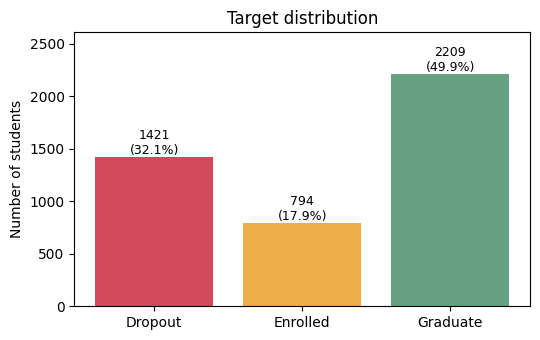

In [5]:
# 4.3 Target distribution and class imbalance. With an imbalanced target accuracy alone can be misleading,
counts = pd.Series(y_all).map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES)
target_table = pd.DataFrame({"count": counts, "percentage": (100 * counts / counts.sum()).round(2)})
display(target_table)
imbalance_ratio = counts.max() / counts.min()
print(f"Imbalance ratio (largest / smallest class): {imbalance_ratio:.2f}")
print(f"Accuracy of a trivial 'always {counts.idxmax()}' classifier: {counts.max() / counts.sum():.4f}")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
bars = ax.bar(CLASS_NAMES, counts.values, color=["#d1495b", "#edae49", "#66a182"])
for b, c in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, c, f"{c}\n({100 * c / counts.sum():.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Number of students"); ax.set_title("Target distribution"); ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
Application order,4424.0,1.728,1.314,0.00,1.00,1.000,2.000,9.000
Previous qualification (grade),4424.0,132.613,13.188,95.00,125.00,133.100,140.000,190.000
Admission grade,4424.0,126.978,14.482,95.00,117.90,126.100,134.800,190.000
Age at enrollment,4424.0,23.265,7.588,17.00,19.00,20.000,25.000,70.000
Curricular units 1st sem (credited),4424.0,0.710,2.361,0.00,0.00,0.000,0.000,20.000
Curricular units 1st sem (enrolled),4424.0,6.271,2.480,0.00,5.00,6.000,7.000,26.000
Curricular units 1st sem (evaluations),4424.0,8.299,4.179,0.00,6.00,8.000,10.000,45.000
Curricular units 1st sem (approved),4424.0,4.707,3.094,0.00,3.00,5.000,6.000,26.000
Curricular units 1st sem (grade),4424.0,10.641,4.844,0.00,11.00,12.286,13.400,18.875
Curricular units 1st sem (without evaluations),4424.0,0.138,0.691,0.00,0.00,0.000,0.000,12.000


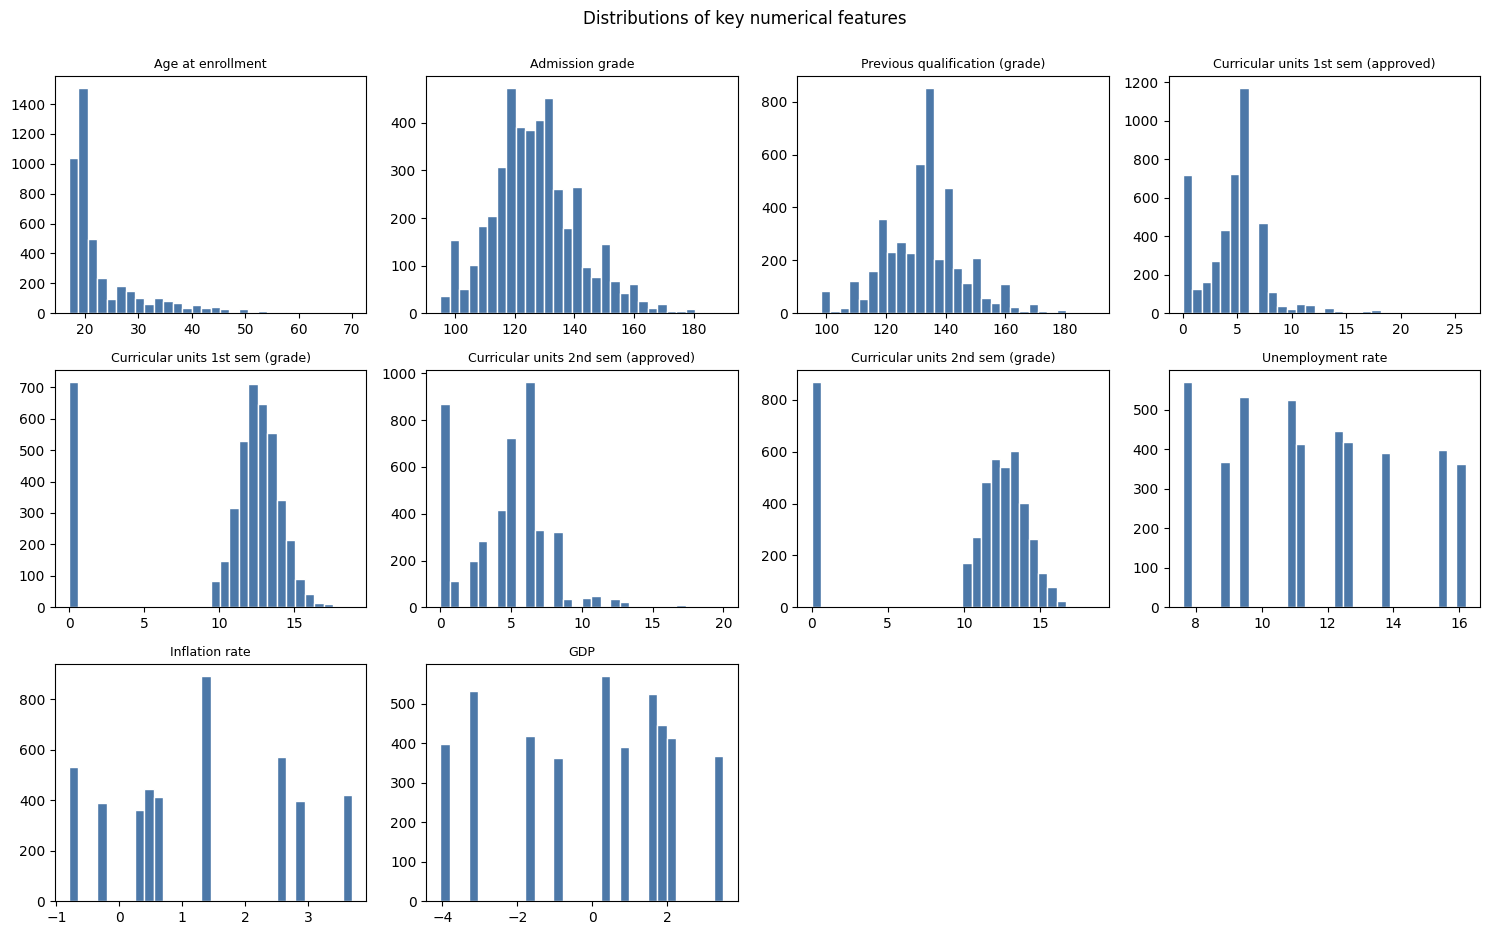

In [6]:
# 4.4 Descriptive statistics and distributions of numerical features
display(X_raw[NUMERICAL_COLS].describe().T.round(3))

lookup = {c.strip().lower(): c for c in X_raw.columns}
key_names = ["age at enrollment", "admission grade", "previous qualification (grade)",
             "curricular units 1st sem (approved)", "curricular units 1st sem (grade)",
             "curricular units 2nd sem (approved)", "curricular units 2nd sem (grade)",
             "unemployment rate", "inflation rate", "gdp"]
key_cols = [lookup[k] for k in key_names if k in lookup and lookup[k] in NUMERICAL_COLS]

n_cols = 4
n_rows = int(np.ceil(len(key_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.1 * n_rows))
for ax, col in zip(np.ravel(axes), key_cols):
    ax.hist(X_raw[col], bins=30, color="#4c78a8", edgecolor="white")
    ax.set_title(col, fontsize=9)
for ax in np.ravel(axes)[len(key_cols):]:
    ax.axis("off")
plt.suptitle("Distributions of key numerical features", y=1.0)
plt.tight_layout(); plt.show()

Target,Dropout,Enrolled,Graduate
Age at enrollment,26.069,22.369,21.784
Admission grade,124.961,125.534,128.794
Previous qualification (grade),131.114,131.208,134.083
Curricular units 1st sem (approved),2.552,4.319,6.232
Curricular units 1st sem (grade),7.257,11.125,12.644
Curricular units 2nd sem (approved),1.940,4.058,6.177
Curricular units 2nd sem (grade),5.899,11.117,12.697
Unemployment rate,11.616,11.273,11.639
Inflation rate,1.284,1.212,1.198
GDP,-0.151,0.053,0.082


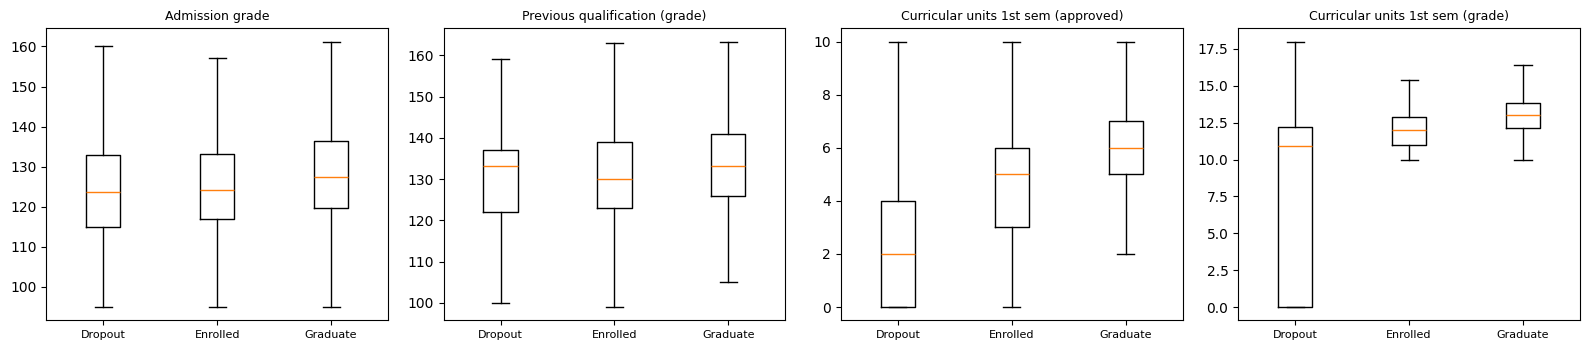

In [7]:
# 4.5 Key features by target class
by_class = X_raw[key_cols].assign(Target=pd.Series(y_all).map(dict(enumerate(CLASS_NAMES))).values)
display(by_class.groupby("Target")[key_cols].mean().reindex(CLASS_NAMES).T.round(3))

box_cols = [c for c in key_cols if "approved" in c.lower() or "grade" in c.lower()][:4]
fig, axes = plt.subplots(1, len(box_cols), figsize=(4 * len(box_cols), 3.6))
for ax, col in zip(np.ravel(axes), box_cols):
    data = [X_raw.loc[y_all == k, col].values for k in range(N_CLASSES)]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, N_CLASSES + 1)); ax.set_xticklabels(CLASS_NAMES)
    ax.set_title(col, fontsize=9); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

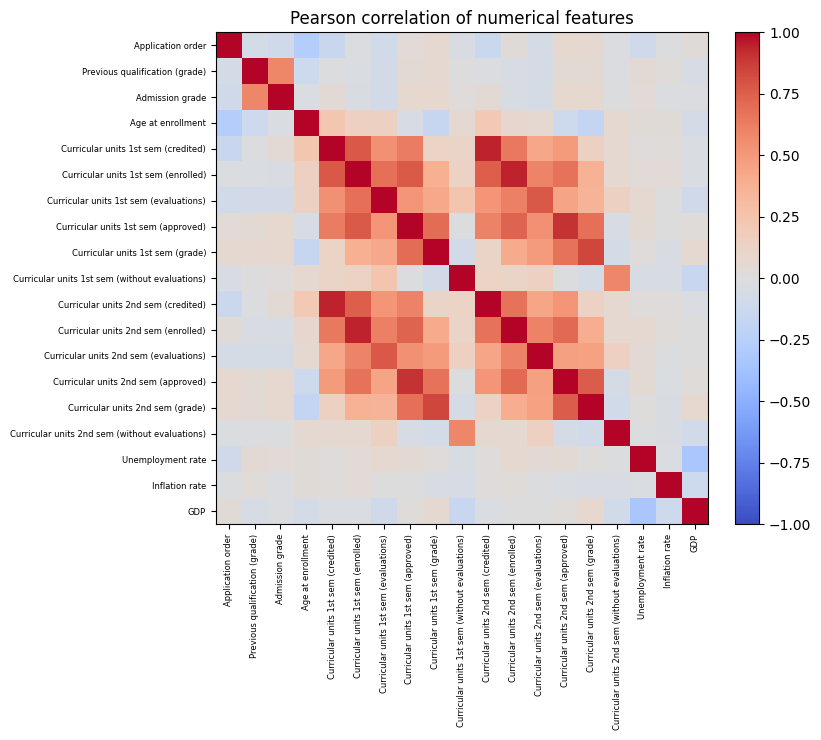

Pairs of numerical features with |r| >= 0.80: 4


,feature A,feature B,correlation
71,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.945
85,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.943
110,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.904
121,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.837



Ten features most correlated with a class indicator (point-biserial r):


,Dropout,Enrolled,Graduate
Curricular units 2nd sem (approved),-0.570,-0.059,0.577
Curricular units 2nd sem (grade),-0.572,0.080,0.473
Curricular units 1st sem (approved),-0.479,-0.059,0.492
Curricular units 1st sem (grade),-0.481,0.047,0.413
Tuition fees up to date,-0.429,0.096,0.327
Scholarship holder,-0.245,-0.092,0.299
Age at enrollment,0.254,-0.055,-0.195
Debtor,0.229,-0.001,-0.214
Gender,0.204,0.034,-0.217
Curricular units 2nd sem (enrolled),-0.142,-0.063,0.180


In [8]:
# 4.6 Correlation analysis (numerical features, strongly correlated pairs, correlation with each class indicator)
corr_cols = [c for c in NUMERICAL_COLS if X_raw[c].std() > 0]
corr = X_raw[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=90, fontsize=6); ax.set_yticklabels(corr_cols, fontsize=6)
plt.colorbar(im, fraction=0.046, pad=0.04); ax.set_title("Pearson correlation of numerical features")
plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("correlation").reset_index().rename(columns={"level_0": "feature A", "level_1": "feature B"}))
strong = pairs[pairs["correlation"].abs() >= 0.80].sort_values("correlation", key=np.abs, ascending=False)
print(f"Pairs of numerical features with |r| >= 0.80: {len(strong)}")
display(strong.head(12).round(3))

# One-vs-rest correlation of every numerical / binary feature with each class indicator
num_bin = [c for c in NUMERICAL_COLS + BINARY_COLS if X_raw[c].std() > 0]
class_corr = pd.DataFrame({CLASS_NAMES[k]: [np.corrcoef(X_raw[c], (y_all == k).astype(float))[0, 1] for c in num_bin]
                           for k in range(N_CLASSES)}, index=num_bin)
top = class_corr.abs().max(axis=1).sort_values(ascending=False).head(10).index
print("\nTen features most correlated with a class indicator (point-biserial r):")
display(class_corr.loc[top].round(3))

In [9]:
# 5. Data Preprocessing
def make_preprocessor():
    """A fresh (unfitted) preprocessing pipeline."""
    return ColumnTransformer(
        transformers=[
            ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL_COLS),
            ("numerical", StandardScaler(), NUMERICAL_COLS),
            ("binary", "passthrough", BINARY_COLS),
        ],
        remainder="drop",
    )


def add_bias(A):
    """Append a constant feature (bias term) as the last column."""
    return np.hstack([A, np.ones((A.shape[0], 1))])


def fit_transform_design(X_fit_raw, *X_other_raw):
    """Fit a new preprocessor on X_fit_raw only; return (preprocessor, X_fit, *X_others) with bias columns."""
    prep = make_preprocessor().fit(X_fit_raw)
    mats = [add_bias(prep.transform(X_fit_raw))] + [add_bias(prep.transform(Z)) for Z in X_other_raw]
    return (prep, *mats)


print("Preprocessing pipeline defined (not fitted yet).")

Preprocessing pipeline defined (not fitted yet).


In [10]:
# 6. Train/Test Split
all_idx = np.arange(len(X_raw))
train_idx, test_idx = train_test_split(all_idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)

X_train_raw, X_test_raw = X_raw.iloc[train_idx].reset_index(drop=True), X_raw.iloc[test_idx].reset_index(drop=True)
y_train, y_test = y_all[train_idx], y_all[test_idx]

preprocessor, X_train, X_test = fit_transform_design(X_train_raw, X_test_raw)   # fitted on TRAIN only
FEATURE_NAMES = list(preprocessor.get_feature_names_out()) + ["bias"]
SPLIT_FINGERPRINT = hashlib.sha256(np.sort(train_idx).tobytes()).hexdigest()[:16]

dist = pd.DataFrame({
    "train (count)": np.bincount(y_train, minlength=N_CLASSES),
    "train (%)": (100 * np.bincount(y_train, minlength=N_CLASSES) / len(y_train)).round(2),
    "test (count)": np.bincount(y_test, minlength=N_CLASSES),
    "test (%)": (100 * np.bincount(y_test, minlength=N_CLASSES) / len(y_test)).round(2),
}, index=CLASS_NAMES)
display(dist)

print(f"Design matrices -> train: {X_train.shape} | test: {X_test.shape}  (incl. bias column)")
num_slice = [i for i, f in enumerate(FEATURE_NAMES) if f.startswith("numerical__")]
print("Max |mean| of scaled numerical features on TRAIN:", float(np.abs(X_train[:, num_slice].mean(axis=0)).max().round(10)))
print("Split fingerprint (must be identical in all notebooks):", SPLIT_FINGERPRINT)

,train (count),train (%),test (count),test (%)
Dropout,1137,32.13,284,32.09
Enrolled,635,17.94,159,17.97
Graduate,1767,49.93,442,49.94


Design matrices -> train: (3539, 237) | test: (885, 237)  (incl. bias column)
Max |mean| of scaled numerical features on TRAIN: 0.0
Split fingerprint (must be identical in all notebooks): 84af02e7b2f6d02b


In [11]:
# 7. SVM Model Implementation
def init_weights(d, k, seed=SEED):
    """Small random initial weights; the same seed gives the same start for every optimizer."""
    return np.random.default_rng(seed).normal(0.0, 0.01, size=(d, k))


def _violations(W, X, y):
    """Scores, most violating wrong class j*, and xi_i = 1 + s_{i,j*} - s_{i,y_i}."""
    n = X.shape[0]
    idx = np.arange(n)
    scores = X @ W                                    # (n, K)
    shifted = scores + 1.0
    shifted[idx, y] = -np.inf                         # exclude the true class from the max
    j_star = shifted.argmax(axis=1)
    xi = shifted[idx, j_star] - scores[idx, y]        # 1 + s_{j*} - s_y
    return j_star, xi


def _l2_term(W, lam):
    return 0.5 * lam * np.sum(W[:-1, :] ** 2)         # last row = bias, not regularised


def cs_loss(W, X, y, lam=LAMBDA):
    """Crammer-Singer hinge loss (mean over samples) + L2 regularisation."""
    _, xi = _violations(W, X, y)
    return float(np.maximum(0.0, xi).mean() + _l2_term(W, lam))


def cs_loss_and_grad(W, X, y, lam=LAMBDA):
    """Objective value and one subgradient with respect to W (shape (d, K))."""
    n = X.shape[0]
    idx = np.arange(n)
    j_star, xi = _violations(W, X, y)
    active = xi > 0.0
    loss = float(np.maximum(0.0, xi).mean() + _l2_term(W, lam))

    G = np.zeros((n, W.shape[1]))
    G[idx[active], j_star[active]] = 1.0              # +x_i for the most violating class
    G[idx[active], y[active]] = -1.0                  # -x_i for the true class
    grad = X.T @ G / n

    reg = lam * W
    reg[-1, :] = 0.0                                  # no regularisation of the bias row
    return loss, grad + reg


def predict(W, X):
    return np.argmax(X @ W, axis=1)


print("Model functions defined: init_weights, cs_loss, cs_loss_and_grad, predict")

Model functions defined: init_weights, cs_loss, cs_loss_and_grad, predict


In [12]:
# 7.2 Verification of the implementation
def cs_loss_bruteforce(W, X, y):
    """Literal implementation of the definition (data term only, lambda = 0)."""
    total = 0.0
    for i in range(X.shape[0]):
        s = X[i] @ W
        worst_wrong = max(s[j] + 1.0 - s[y[i]] for j in range(W.shape[1]) if j != y[i])
        total += max(0.0, worst_wrong)
    return total / X.shape[0]


rng = np.random.default_rng(0)
Xc, yc = X_train[:300], y_train[:300]
Wc = rng.normal(0.0, 0.2, size=(X_train.shape[1], N_CLASSES))

# 1) vectorised vs brute force
v, b = cs_loss(Wc, Xc, yc, lam=0.0), cs_loss_bruteforce(Wc, Xc, yc)
print(f"1) vectorised loss = {v:.10f} | brute force = {b:.10f} | abs diff = {abs(v - b):.2e}")
assert abs(v - b) < 1e-10

# 2) W = 0  ->  data loss must be exactly 1
z = cs_loss(np.zeros_like(Wc), Xc, yc, lam=0.0)
print(f"2) loss at W = 0: {z:.10f} (expected 1.0)")
assert abs(z - 1.0) < 1e-12

# 3) numerical gradient check on random coordinates (incl. the bias row)
_, g = cs_loss_and_grad(Wc, Xc, yc, LAMBDA)
h, worst = 1e-6, 0.0
coords = [(int(rng.integers(0, Wc.shape[0])), int(rng.integers(0, N_CLASSES))) for _ in range(25)]
coords += [(Wc.shape[0] - 1, k) for k in range(N_CLASSES)]
for (i, j) in coords:
    Wp, Wm = Wc.copy(), Wc.copy()
    Wp[i, j] += h
    Wm[i, j] -= h
    num = (cs_loss(Wp, Xc, yc, LAMBDA) - cs_loss(Wm, Xc, yc, LAMBDA)) / (2 * h)
    worst = max(worst, abs(num - g[i, j]) / max(1.0, abs(num), abs(g[i, j])))
print(f"3) numerical gradient check on {len(coords)} coordinates: max relative error = {worst:.2e}")
assert worst < 1e-5
print("\nAll verification checks passed.")

1) vectorised loss = 1.5224866564 | brute force = 1.5224866564 | abs diff = 6.66e-16
2) loss at W = 0: 1.0000000000 (expected 1.0)
3) numerical gradient check on 28 coordinates: max relative error = 1.56e-10

All verification checks passed.


In [13]:
# 8. Optimization Algorithm Implementation
MOMENTUM = 0.9          # momentum coefficient (mu)
BATCH_SIZE = 64         # mini-batch size
HPARAMS = {"momentum": MOMENTUM, "epochs": EPOCHS, "lambda": LAMBDA, "batch_size": BATCH_SIZE}

In [14]:
def train_optimizer(X, y, lr, epochs=EPOCHS, lam=LAMBDA, momentum=MOMENTUM,
                    batch_size=BATCH_SIZE, seed=SEED):
    """Mini-batch gradient descent with momentum.

    Returns the learned weight matrix and a history dictionary with
    the full-training-set objective after every epoch (index 0 = initial value)
    and the wall-clock time spent in the parameter updates of each epoch.
    """
    n, d = X.shape
    W = init_weights(d, N_CLASSES, seed)
    velocity = np.zeros_like(W)
    rng = np.random.default_rng(seed)
    losses = [cs_loss(W, X, y, lam)]
    epoch_times = []
    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        perm = rng.permutation(n)                                  # reshuffle every epoch
        for start in range(0, n, batch_size):
            b = perm[start:start + batch_size]
            _, grad = cs_loss_and_grad(W, X[b], y[b], lam)
            velocity = momentum * velocity + grad
            W = W - lr * velocity
        epoch_times.append(time.perf_counter() - t0)
        losses.append(cs_loss(W, X, y, lam))
    return W, {"loss": losses, "epoch_time": epoch_times}

In [15]:
# 9. Model Training
LR_GRID = [3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]

sweep_rows = []
for lr in LR_GRID:
    _, hist_c = train_optimizer(X_train, y_train, lr=lr)
    final_loss = hist_c["loss"][-1]
    ok = bool(np.isfinite(final_loss)) and final_loss < 10 * hist_c["loss"][0]
    sweep_rows.append({"learning rate": lr, "final training loss": final_loss if ok else np.nan,
                       "update time (s)": sum(hist_c["epoch_time"]), "status": "ok" if ok else "diverged"})

sweep = pd.DataFrame(sweep_rows)
display(sweep)
BEST_LR = float(sweep.loc[sweep["final training loss"].idxmin(), "learning rate"])
print(f"Selected learning rate (lowest final training loss): {BEST_LR}")
if BEST_LR in (min(LR_GRID), max(LR_GRID)):
    print("Note: the best value lies on the border of the grid; a wider grid might improve the result.")

,learning rate,final training loss,update time (s),status
0,0.00003,0.559099,1.213332,ok
1,0.00010,0.519783,1.242969,ok
2,0.00030,0.489258,1.186411,ok
3,0.00100,0.469859,1.209033,ok
4,0.00300,0.459357,1.292014,ok
5,0.01000,0.458435,1.264291,ok
6,0.03000,0.480684,1.207204,ok


Selected learning rate (lowest final training loss): 0.01


In [16]:
# 9.2 Final training on the whole training set with the selected learning rate
t_start = time.perf_counter()
W, history = train_optimizer(X_train, y_train, lr=BEST_LR)
total_wall_time = time.perf_counter() - t_start

losses = np.array(history["loss"])
print(f"Optimizer           : {OPTIMIZER_NAME}")
print(f"Learning rate       : {BEST_LR}")
print(f"Initial loss        : {losses[0]:.4f}")
print(f"Final training loss : {losses[-1]:.4f}  (after {EPOCHS} epochs)")
print(f"Update time (sum)   : {sum(history['epoch_time']):.2f} s | total incl. loss logging: {total_wall_time:.2f} s")

Optimizer           : Mini-Batch GD + Momentum
Learning rate       : 0.01
Initial loss        : 1.0142
Final training loss : 0.4584  (after 100 epochs)
Update time (sum)   : 1.20 s | total incl. loss logging: 1.33 s


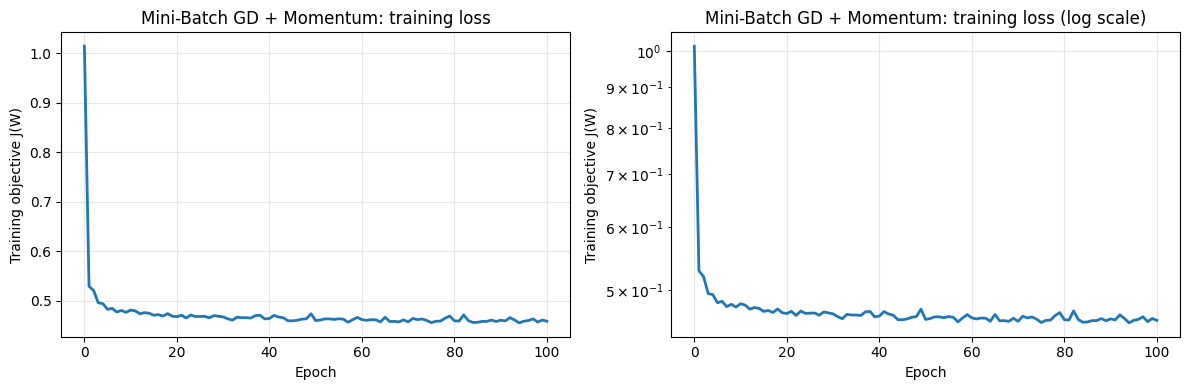

In [17]:

# 10. Loss Curve Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, logy in zip(axes, [False, True]):
    ax.plot(np.arange(len(losses)), losses, color="#1f77b4", lw=2)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Training objective J(W)")
    ax.set_title(f"{OPTIMIZER_NAME}: training loss" + (" (log scale)" if logy else ""))
    if logy:
        ax.set_yscale("log")
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [18]:
# 11. Model Evaluation
y_pred = predict(W, X_test)
acc = accuracy_score(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)

metrics = {"accuracy": float(acc), "precision_macro": float(prec), "recall_macro": float(rec),
           "f1_macro": float(f1), "final_train_loss": float(losses[-1])}
display(pd.DataFrame(metrics, index=[OPTIMIZER_NAME]).round(4))

,accuracy,precision_macro,recall_macro,f1_macro,final_train_loss
Mini-Batch GD + Momentum,0.7695,0.7109,0.6659,0.6724,0.4584


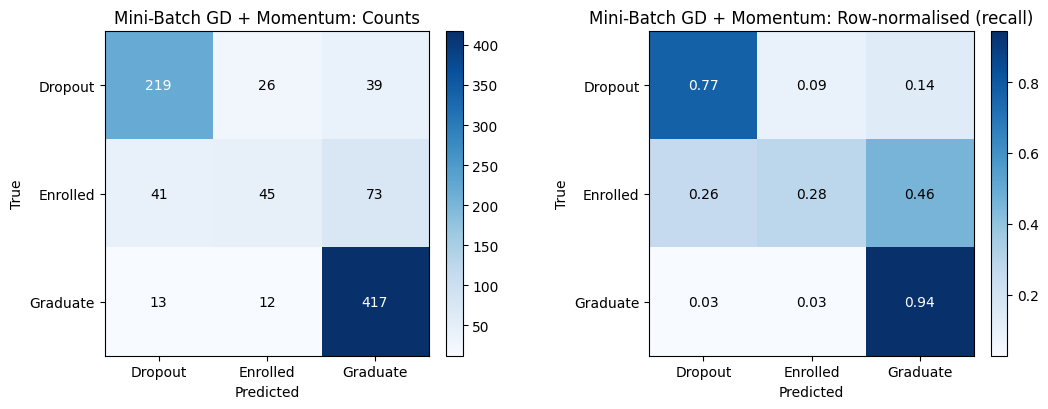

In [19]:

# 12. Confusion Matrix

cm = confusion_matrix(y_test, y_pred, labels=range(N_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, M, title, fmt in [(axes[0], cm, "Counts", "{:d}"), (axes[1], cm_norm, "Row-normalised (recall)", "{:.2f}")]:
    im = ax.imshow(M, cmap="Blues")
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{OPTIMIZER_NAME}: {title}")
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center",
                    color="white" if M[i, j] > M.max() / 2 else "black")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

In [20]:
# 13. Classification Report
# Per-class precision / recall / F1 on the test set.
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0, output_dict=True)

              precision    recall  f1-score   support

     Dropout     0.8022    0.7711    0.7864       284
    Enrolled     0.5422    0.2830    0.3719       159
    Graduate     0.7883    0.9434    0.8589       442

    accuracy                         0.7695       885
   macro avg     0.7109    0.6659    0.6724       885
weighted avg     0.7485    0.7695    0.7481       885



In [21]:

# 14. Final Results and Interpretation
loss0, lossN, lossMin = losses[0], losses[-1], losses.min()
target95 = loss0 - 0.95 * (loss0 - lossMin)
epochs_to_95 = int(np.argmax(losses <= target95))                       # first epoch reaching 95% of the total reduction
time_to_95 = float(np.sum(history["epoch_time"][:epochs_to_95]))
n_increases = int(np.sum(np.diff(losses) > 1e-12))                      # epochs in which the loss went up
rel_reduction = 100 * (loss0 - lossN) / loss0

# ---- per-class results ----
f1_by_class = {c: report[c]["f1-score"] for c in CLASS_NAMES}
rec_by_class = {c: report[c]["recall"] for c in CLASS_NAMES}
weakest = min(f1_by_class, key=f1_by_class.get)
strongest = max(f1_by_class, key=f1_by_class.get)
off = cm.copy(); np.fill_diagonal(off, 0)
ti, pj = np.unravel_index(off.argmax(), off.shape)

print(f"=== {OPTIMIZER_NAME} : summary of measured results ===")
print(f"* Learning rate selected (lowest final training loss): {BEST_LR}")
print(f"* The objective decreased from {loss0:.4f} to {lossN:.4f} ({rel_reduction:.1f}% reduction) in {EPOCHS} epochs.")
print(f"* 95% of the total loss reduction was reached after {epochs_to_95} epoch(s) ({time_to_95:.2f} s of update time).")
print(f"* The training loss increased in {n_increases} of {EPOCHS} epochs "
      f"({'smooth, essentially monotone curve' if n_increases <= 0.05 * EPOCHS else 'noticeably oscillating curve'}).")
print(f"* Test accuracy {metrics['accuracy']:.4f} vs macro-F1 {metrics['f1_macro']:.4f} "
      f"(gap {metrics['accuracy'] - metrics['f1_macro']:+.4f}; a positive gap means the larger classes are recognised better than the average class).")
print(f"* Best class: {strongest} (F1 = {f1_by_class[strongest]:.4f}); weakest class: {weakest} (F1 = {f1_by_class[weakest]:.4f}, recall = {rec_by_class[weakest]:.4f}).")
print(f"* Most frequent error: true '{CLASS_NAMES[ti]}' predicted as '{CLASS_NAMES[pj]}' ({int(off[ti, pj])} test samples).")

# ---- save results for the comparison notebook ----
os.makedirs(RESULTS_DIR, exist_ok=True)
result = {
    "optimizer": OPTIMIZER_NAME, "slug": OPTIMIZER_SLUG, "data_source": DATA_SOURCE,
    "seed": SEED, "split_fingerprint": SPLIT_FINGERPRINT,
    "n_train": int(X_train.shape[0]), "n_test": int(X_test.shape[0]), "n_features": int(X_train.shape[1]),
    "learning_rate": BEST_LR, "learning_rate_grid": [float(v) for v in LR_GRID],
    "hyperparameters": {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in HPARAMS.items()},
    "metrics": metrics,
    "per_class": {c: {k: float(report[c][k]) for k in ("precision", "recall", "f1-score")} | {"support": int(report[c]["support"])}
                  for c in CLASS_NAMES},
    "confusion_matrix": cm.tolist(),
    "loss_history": [float(v) for v in losses],
    "epoch_time": [float(v) for v in history["epoch_time"]],
    "convergence": {"epochs_to_95pct_reduction": epochs_to_95, "time_to_95pct_reduction_sec": time_to_95,
                    "epochs_with_loss_increase": n_increases, "total_update_time_sec": float(sum(history["epoch_time"]))},
}
with open(os.path.join(RESULTS_DIR, f"{OPTIMIZER_SLUG}.json"), "w") as fh:
    json.dump(result, fh, indent=2)
print(f"\nSaved -> {RESULTS_DIR}/{OPTIMIZER_SLUG}.json")

=== Mini-Batch GD + Momentum : summary of measured results ===
* Learning rate selected (lowest final training loss): 0.01
* The objective decreased from 1.0142 to 0.4584 (54.8% reduction) in 100 epochs.
* 95% of the total loss reduction was reached after 5 epoch(s) (0.06 s of update time).
* The training loss increased in 47 of 100 epochs (noticeably oscillating curve).
* Test accuracy 0.7695 vs macro-F1 0.6724 (gap +0.0971; a positive gap means the larger classes are recognised better than the average class).
* Best class: Graduate (F1 = 0.8589); weakest class: Enrolled (F1 = 0.3719, recall = 0.2830).
* Most frequent error: true 'Enrolled' predicted as 'Graduate' (73 test samples).

Saved -> results/mini-batch-gd.json
